# Kerr quasinormal modes with Leaver's method

From the course [*Black-hole perturbation theory*](https://svykho.github.io/lab/course/) by Alejandro Svyatkovskyy Kholyavka, [Lesson 12: Compute it yourself](https://svykho.github.io/lab/course/compute.html).

A spinning black hole rings at frequencies that depend on its spin and split according to the azimuthal number $m$ ([Lesson 9](https://svykho.github.io/lab/course/kerr.html)). This notebook computes them with Leaver's method for Kerr (1985): two continued fractions, one for the angular equation and one for the radial, solved together. It reproduces the figure "Spin splits the spectrum" of Lesson 9. It needs only NumPy and Matplotlib and runs in a few seconds.

Units: $G = c = M = 1$. As for Schwarzschild, Leaver uses $2M = 1$ inside, so $a = \chi/2$ and the code works with $2M\omega$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

S = -2  # spin weight of gravitational perturbations (psi_4)

## The angular equation

The Teukolsky equation separates into an angular part, solved by spin-weighted spheroidal harmonics, and a radial part. The angular equation depends on $c = a\omega$ and has a separation constant $A$ (with $A = (\ell - s)(\ell + s + 1)$ at $c = 0$, which is 4 for $\ell = 2$, $s = -2$). Expanding the angular function in powers of $1 + \cos\theta$ gives a three-term recurrence, and $A$ is fixed by the vanishing of its continued fraction. The inversion index is $\ell - \max(|m|, |s|)$, the number of the root we want.

In [2]:
def angular_cf(A, w, a, l, m, s=S, depth=300):
    k1, k2 = abs(m - s) / 2, abs(m + s) / 2
    c = a * w

    def alpha(n):
        return -2 * (n + 1) * (n + 2 * k1 + 1)

    def beta(n):
        return (n * (n - 1) + 2 * n * (k1 + k2 + 1 - 2 * c)
                - (2 * c * (2 * k1 + s + 1) - (k1 + k2) * (k1 + k2 + 1)) - (c * c + s * (s + 1) + A))

    def gamma(n):
        return 2 * c * (n + k1 + k2 + s)

    N = l - max(abs(m), abs(s))
    tail = 0j
    for n in range(depth, N, -1):
        tail = alpha(n - 1) * gamma(n) / (beta(n) - tail)
    head = 0j
    if N > 0:
        x = beta(0)
        for n in range(1, N):
            x = beta(n) - alpha(n - 1) * gamma(n) / x
        head = alpha(N - 1) * gamma(N) / x
    return beta(N) - tail - head

## The radial equation

The radial function is written as a prefactor with the right behaviour at the horizon and at infinity, times a power series in $(r - r_+)/(r - r_-)$. Its coefficients obey another three-term recurrence (Leaver 1985), with coefficients that depend on $\omega$, $a$, $m$ and $A$. With $b = \sqrt{1 - 4a^2}$, which is the distance between the two horizons in these units:

In [3]:
def radial_cf(w, A, a, m, n=0, s=S, depth=2000):
    b = np.sqrt(1 - 4 * a * a)
    q = w / 2 - a * m
    c0 = 1 - s - 1j * w - (2j / b) * q
    c1 = -4 + 2j * w * (2 + b) + (4j / b) * q
    c2 = s + 3 - 3j * w - (2j / b) * q
    c3 = w * w * (4 + 2 * b - a * a) - 2 * a * m * w - s - 1 + (2 + b) * 1j * w - A + ((4 * w + 2j) / b) * q
    c4 = s + 1 - 2 * w * w - (2 * s + 3) * 1j * w - ((4 * w + 2j) / b) * q

    def alpha(k):
        return k * k + (c0 + 1) * k + c0

    def beta(k):
        return -2 * k * k + (c1 + 2) * k + c3

    def gamma(k):
        return k * k + (c2 - 3) * k + c4 - c2 + 2

    tail = 0j
    for k in range(depth, n, -1):
        tail = alpha(k - 1) * gamma(k) / (beta(k) - tail)
    head = 0j
    if n > 0:
        x = beta(0)
        for k in range(1, n):
            x = beta(k) - alpha(k - 1) * gamma(k) / x
        head = alpha(n - 1) * gamma(n) / x
    return beta(n) - tail - head

## Solving both at once

For a trial frequency $\omega$, first solve the angular equation for $A$, then evaluate the radial continued fraction with that $A$. A quasinormal mode is a zero of the result. Both zeros are found with the secant method, each starting from the previous answer.

In [4]:
def secant(f, x0, x1, tol=1e-12, maxit=60):
    f0, f1 = f(x0), f(x1)
    for _ in range(maxit):
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        if abs(x2 - x1) < tol * max(1.0, abs(x2)):
            return x2
        x0, f0, x1, f1 = x1, f1, x2, f(x2)
    raise RuntimeError("the secant method did not converge")


def kerr_qnm(chi, l, m, n, w_guess, A_guess, depth=2000):
    """Returns 2M*omega and A for spin chi, starting from guesses (units 2M = 1)."""
    a = chi / 2
    state = {"A": A_guess}

    def f(w):
        state["A"] = secant(lambda A: angular_cf(A, w, a, l, m), state["A"], state["A"] + 1e-3)
        return radial_cf(w, state["A"], a, m, n, depth=depth)

    w = secant(f, w_guess, w_guess * (1 + 1e-4))
    f(w)
    return w, state["A"]


# Schwarzschild first: the l = 2 fundamental mode, A = 4
w, A = kerr_qnm(0.0, 2, 2, 0, 0.7473 - 0.1779j, 4.0)
print(f"chi = 0:  M omega = {w / 2:.6f},  A = {A:.6f}")

chi = 0:  M omega = 0.373672-0.088962j,  A = 4.000000+0.000000j


## Following a mode as the spin grows

Start from Schwarzschild and increase the spin in small steps, using the last two answers to predict the next one. This is called continuation, and it keeps each mode on its own branch. Near $\chi = 1$ the modes change fast and the continued fraction converges slowly, so the steps get smaller and the fraction deeper.

In [5]:
def follow(l, m, n, chis, w0, A0):
    out = []
    prev = []
    for chi in chis:
        if len(prev) >= 2:
            (c1, w1, A1), (c2, w2, A2) = prev[-2], prev[-1]
            t = (chi - c2) / (c2 - c1)
            wg, Ag = w2 + t * (w2 - w1), A2 + t * (A2 - A1)
        elif prev:
            wg, Ag = prev[-1][1], prev[-1][2]
        else:
            wg, Ag = w0, A0
        depth = 1000 if chi < 0.9 else 4000
        w, A = kerr_qnm(chi, l, m, n, wg, Ag, depth)
        prev.append((chi, w, A))
        out.append(w / 2)  # back to M omega
    return np.array(out)


chis = np.concatenate([np.arange(0, 0.9, 0.025), np.arange(0.9, 0.99, 0.01), [0.99]])
modes = {}
for m in (2, 1, 0, -1, -2):
    modes[m] = follow(2, m, 0, chis, 0.747343 - 0.177925j, 4.0)
    print(f"m = {m:+d}:  chi = 0.9 -> M omega = {modes[m][chis.searchsorted(0.9 - 1e-9)]:.6f}"
          f"   chi = 0.99 -> {modes[m][-1]:.6f}")

m = +2:  chi = 0.9 -> M omega = 0.671614-0.064869j   chi = 0.99 -> 0.870893-0.029390j


m = +1:  chi = 0.9 -> M omega = 0.516291-0.069804j   chi = 0.99 -> 0.572749-0.046208j


m = +0:  chi = 0.9 -> M omega = 0.412004-0.078483j   chi = 0.99 -> 0.423685-0.072701j


m = -1:  chi = 0.9 -> M omega = 0.344359-0.084865j   chi = 0.99 -> 0.343890-0.083551j


m = -2:  chi = 0.9 -> M omega = 0.297244-0.088281j   chi = 0.99 -> 0.292107-0.088052j


Lesson 9 quotes the $\ell = m = 2$ mode at $\chi = 0.99$ as $M\omega = 0.871$ with a quality factor of almost 15. The values used in the course were computed with 25 digits; here is the comparison:

In [6]:
course = {0.5: 0.464123 - 0.085639j, 0.7: 0.532600 - 0.080793j, 0.9: 0.671614 - 0.064869j, 0.99: 0.870893 - 0.029390j}
for chi, ref in course.items():
    w = modes[2][np.argmin(abs(chis - chi))]
    print(f"chi = {chi}:  {w:.6f}   course {ref:.6f}   difference {abs(w - ref):.1e}")
Q = modes[2].real / (2 * abs(modes[2].imag))
print(f"quality factor at chi = 0.99: {Q[-1]:.1f}")

chi = 0.5:  0.464123-0.085639j   course 0.464123-0.085639j   difference 1.7e-07
chi = 0.7:  0.532600-0.080793j   course 0.532600-0.080793j   difference 2.7e-07
chi = 0.9:  0.671614-0.064869j   course 0.671614-0.064869j   difference 3.6e-07
chi = 0.99:  0.870893-0.029390j   course 0.870893-0.029390j   difference 5.4e-07
quality factor at chi = 0.99: 14.8


## Spin splits the spectrum

The five $\ell = 2$ fundamental modes, which coincide for Schwarzschild, separate as the spin grows: co-rotating modes ($m > 0$) rise in pitch and live longer, counter-rotating ones drop.

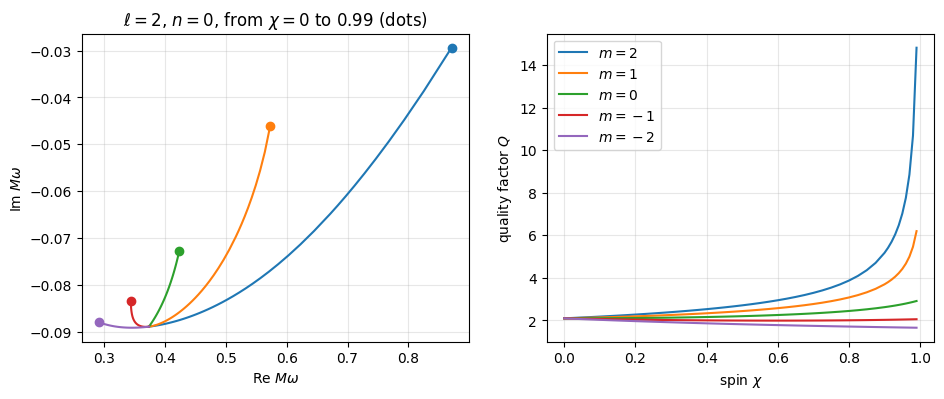

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for m in (2, 1, 0, -1, -2):
    w = modes[m]
    a1.plot(w.real, w.imag, "-", label=f"$m = {m}$")
    a1.plot(w[-1].real, w[-1].imag, "o", color=a1.lines[-1].get_color())
    a2.plot(chis, w.real / (2 * abs(w.imag)), label=f"$m = {m}$")
a1.set_xlabel(r"Re $M\omega$")
a1.set_ylabel(r"Im $M\omega$")
a1.set_title(r"$\ell = 2$, $n = 0$, from $\chi = 0$ to $0.99$ (dots)")
a2.set_xlabel(r"spin $\chi$")
a2.set_ylabel(r"quality factor $Q$")
a2.legend()
plt.show()

## Spectroscopy

The exercise of Lesson 9: a ringdown with $f = 250$ Hz and $\tau = 4$ ms, assumed to be the $\ell = m = 2$ mode. Its quality factor $Q = \pi f \tau$ fixes the spin; then $\operatorname{Re} M\omega$ at that spin fixes the mass.

In [8]:
f_hz, tau = 250.0, 4e-3
Q_obs = np.pi * f_hz * tau
chi_obs = np.interp(Q_obs, Q, chis)
w_obs = np.interp(chi_obs, chis, modes[2].real) + 1j * np.interp(chi_obs, chis, modes[2].imag)
T_sun = 4.925491e-6  # G M_sun / c^3 in seconds
M = w_obs.real / (2 * np.pi * f_hz * T_sun)
print(f"Q = {Q_obs:.2f}  ->  chi = {chi_obs:.3f},  M omega = {w_obs:.4f},  M = {M:.1f} solar masses")
print(f"check: tau = {M * T_sun / abs(w_obs.imag) * 1e3:.2f} ms")

Q = 3.14  ->  chi = 0.660,  M omega = 0.5161-0.0821j,  M = 66.7 solar masses
check: tau = 4.00 ms


## Try this

- Follow the first overtone, $n = 1$ (start from $2M\omega = 0.693422 - 0.547830\,i$). Near $\chi = 1$ it approaches the fundamental mode.
- Compute the $\ell = m = 3$ mode (start from $2M\omega = 1.198887 - 0.185406\,i$ and $A = 10$).
- Check that as $\chi \to 1$ the $\ell = m = 2$ frequency approaches $m\,\Omega_H$, with $\Omega_H = \chi/(2r_+)$ and $r_+ = 1 + \sqrt{1 - \chi^2}$ (Lesson 9).